

⸻

 ## Capstone Project (Covid 19)

Using Python, Plotly & Facebook Prophet

⸻

## Prepared By : **Yogesh Bahl**

⸻

Project Overview

This project analyzes worldwide COVID-19 trends using:
	•	Python (Pandas, NumPy)
	•	Interactive Data Visualizations (Plotly)
	•	Time-Series Forecasting (Facebook Prophet)

The goal is to study infection and recovery patterns and predict future case trends.

⸻

Dataset Used

covid_19_clean_complete.csv (loads automatically from this GitHub repo)
Contains global data on:
	•	Confirmed cases
	•	Deaths
	•	Recoveries
	•	Active cases
	•	Geographical distribution
	•	Daily progression over time

⸻

Project Objectives
	1.	Clean and preprocess COVID-19 data
	2.	Analyze global infection, recovery & mortality trends
	3.	Visualize patterns using interactive plots
	4.	Compute daily new cases and rate changes
	5.	Forecast future cases using Prophet
	6.	Present results in clear, easy-to-read visuals

⸻

🛠 Tools & Technologies

Category	Tools
Programming	Python
Libraries	Pandas, NumPy, Plotly, Matplotlib
Forecasting	Facebook Prophet
Notebook	Google Colab


⸻

📈 Final Deliverables
	•	Global COVID-19 trend analysis
	•	Daily new cases calculation
	•	Infection & recovery rate visualization
	•	Prophet forecast for next 7 days
	•	Visual explanations & insights

⸻


## 1. Install & Import Libraries

In [1]:
!pip install plotly prophet --quiet

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
from prophet import Prophet
import warnings
warnings.filterwarnings("ignore")

##  2. Load Dataset

In [5]:
# Loads the dataset straight from GitHub - no upload needed
df = pd.read_csv("https://raw.githubusercontent.com/yogeshkbahl/Capstone-covid-19-forecasting-analysis/main/covid_19_clean_complete.csv")
df.head()

,Province/State,Country/Region,Lat,Long,Date,Confirmed,Deaths,Recovered,Active,WHO Region
0,NaN,Afghanistan,33.93911,67.709953,2020-01-22,0,0,0,0,Eastern Mediterranean
1,NaN,Albania,41.15330,20.168300,2020-01-22,0,0,0,0,Europe
2,NaN,Algeria,28.03390,1.659600,2020-01-22,0,0,0,0,Africa
3,NaN,Andorra,42.50630,1.521800,2020-01-22,0,0,0,0,Europe
4,NaN,Angola,-11.20270,17.873900,2020-01-22,0,0,0,0,Africa


## 3. Data Overview

In [6]:
df.info()
df.describe()
df.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49068 entries, 0 to 49067
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Province/State  14664 non-null  object 
 1   Country/Region  49068 non-null  object 
 2   Lat             49068 non-null  float64
 3   Long            49068 non-null  float64
 4   Date            49068 non-null  object 
 5   Confirmed       49068 non-null  int64  
 6   Deaths          49068 non-null  int64  
 7   Recovered       49068 non-null  int64  
 8   Active          49068 non-null  int64  
 9   WHO Region      49068 non-null  object 
dtypes: float64(2), int64(4), object(4)
memory usage: 3.7+ MB


,0
Province/State,34404
Country/Region,0
Lat,0
Long,0
Date,0
Confirmed,0
Deaths,0
Recovered,0
Active,0
WHO Region,0


## 4. Convert Date Column to Datetime

In [7]:
df['Date'] = pd.to_datetime(df['Date'])

## 5. Global Daily Aggregation

In [8]:
global_df = df.groupby("Date")[["Confirmed", "Deaths", "Recovered", "Active"]].sum().reset_index()
global_df.tail()

,Date,Confirmed,Deaths,Recovered,Active
183,2020-07-23,15510481,633506,8710969,6166006
184,2020-07-24,15791645,639650,8939705,6212290
185,2020-07-25,16047190,644517,9158743,6243930
186,2020-07-26,16251796,648621,9293464,6309711
187,2020-07-27,16480485,654036,9468087,6358362


## 6.  Plot Global Trend of Confirmed, Deaths, Recovered, Active

In [9]:
fig = px.line(
    global_df,
    x="Date",
    y=["Confirmed", "Deaths", "Recovered", "Active"],
    title="Global COVID-19 Trends",
    labels={"value": "Count", "Date": "Date"}
)
fig.show()

## 7. Daily New Cases Calculation

In [10]:
global_df["Daily_confirmed"] = global_df["Confirmed"].diff().fillna(0)
global_df["Daily_deaths"] = global_df["Deaths"].diff().fillna(0)
global_df["Daily_recovered"] = global_df["Recovered"].diff().fillna(0)
global_df.tail()

,Date,Confirmed,Deaths,Recovered,Active
183,2020-07-23,15510481,633506,8710969,6166006
184,2020-07-24,15791645,639650,8939705,6212290
185,2020-07-25,16047190,644517,9158743,6243930
186,2020-07-26,16251796,648621,9293464,6309711
187,2020-07-27,16480485,654036,9468087,6358362


## 8. Plot Daily New Confirmed Cases

In [12]:
global_df["Daily_confirmed"] = global_df["Confirmed"].diff().fillna(0)
fig = px.line(
    global_df,
    x="Date",
    y="Daily_confirmed",
    title="Daily New COVID-19 Cases"
)
fig.show()

##  9. Calculate Infection Rate & Recovery Rate

In [14]:
global_df["Daily_confirmed"] = global_df["Confirmed"].diff().fillna(0)
global_df["Daily_deaths"] = global_df["Deaths"].diff().fillna(0)
global_df["Daily_recovered"] = global_df["Recovered"].diff().fillna(0)
global_df["Infection_Rate"] = global_df["Daily_confirmed"].pct_change().fillna(0)
global_df["Recovery_Rate"] = global_df["Daily_recovered"].pct_change().fillna(0)
global_df.head()

,Date,Confirmed,Deaths,Recovered,Active,Daily_confirmed,Infection_Rate,Daily_deaths,Daily_recovered,Recovery_Rate
0,2020-01-22,555,17,28,510,0.0,0.000000,0.0,0.0,0.000000
1,2020-01-23,654,18,30,606,99.0,inf,1.0,2.0,inf
2,2020-01-24,941,26,36,879,287.0,1.898990,8.0,6.0,2.000000
3,2020-01-25,1434,42,39,1353,493.0,0.717770,16.0,3.0,-0.500000
4,2020-01-26,2118,56,52,2010,684.0,0.387424,14.0,13.0,3.333333


## 10. Plot Infection & Recovery Rates

In [15]:
fig = px.line(
    global_df,
    x="Date",
    y=["Infection_Rate", "Recovery_Rate"],
    title="Infection Rate vs Recovery Rate"
)
fig.show()

## 11. FORECASTING USING FACEBOOK PROPHET

- Prepare Data for Prophet

- Prophet requires columns: ds (date) and y (value)

- We’ll forecast Confirmed Cases.

In [16]:
forecast_df = global_df[["Date", "Confirmed"]].rename(columns={"Date": "ds", "Confirmed": "y"})
forecast_df.tail()

,ds,y
183,2020-07-23,15510481
184,2020-07-24,15791645
185,2020-07-25,16047190
186,2020-07-26,16251796
187,2020-07-27,16480485


## 12. Build & Train Prophet Model

In [17]:
model = Prophet()
model.fit(forecast_df)

INFO:prophet:Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


## 13. Make Predictions for Next 7 Days

In [18]:
future = model.make_future_dataframe(periods=7)
forecast = model.predict(future)

forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail(10)

,ds,yhat,yhat_lower,yhat_upper
185,2020-07-25,1.573883e+07,1.563792e+07,1.584650e+07
186,2020-07-26,1.593637e+07,1.582831e+07,1.604067e+07
187,2020-07-27,1.613096e+07,1.602162e+07,1.623317e+07
188,2020-07-28,1.632021e+07,1.621619e+07,1.642143e+07
189,2020-07-29,1.652998e+07,1.642974e+07,1.663122e+07
190,2020-07-30,1.674392e+07,1.664448e+07,1.685368e+07
191,2020-07-31,1.695911e+07,1.685061e+07,1.706643e+07
192,2020-08-01,1.716677e+07,1.706401e+07,1.728436e+07
193,2020-08-02,1.736430e+07,1.725390e+07,1.747278e+07
194,2020-08-03,1.755889e+07,1.744201e+07,1.768117e+07


## 14. Plot Forecast

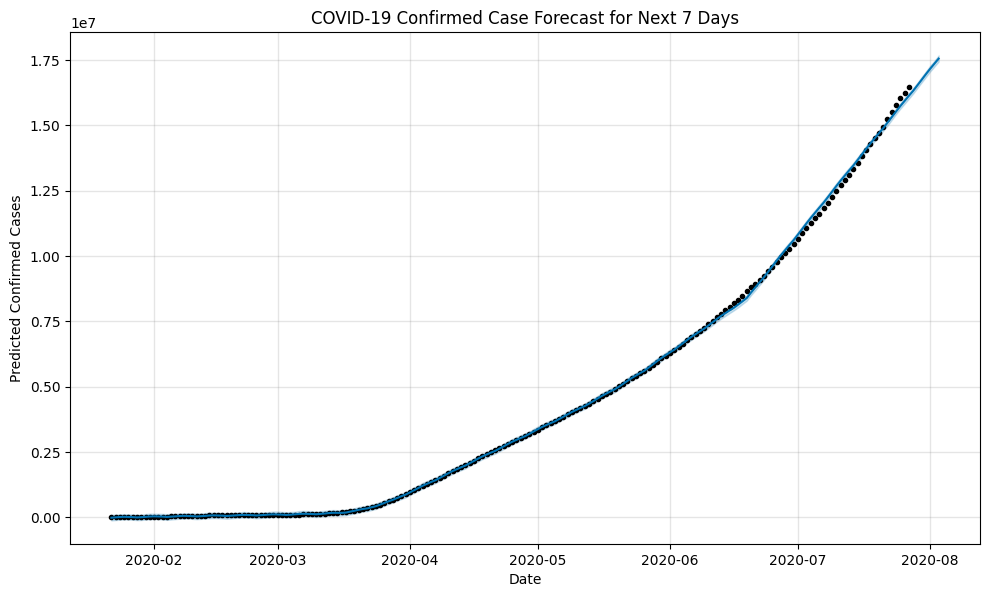

In [19]:
fig1 = model.plot(forecast)
plt.title("COVID-19 Confirmed Case Forecast for Next 7 Days")
plt.xlabel("Date")
plt.ylabel("Predicted Confirmed Cases")
plt.show()

## 15. Prophet Components

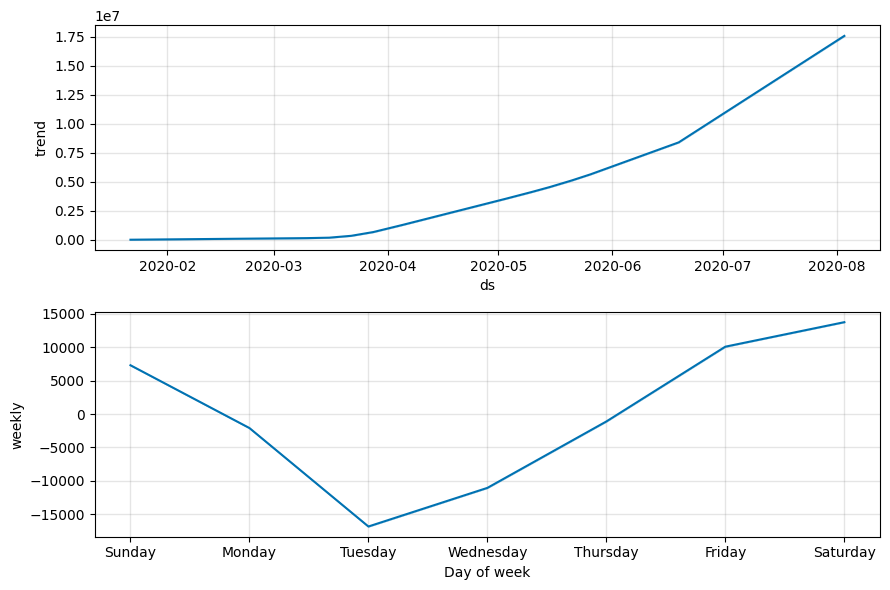

In [20]:
fig2 = model.plot_components(forecast)
plt.show()


⸻

## CONCLUSION (for final report)

✔ Global COVID-19 cases show a strong upward trend in confirmed & recovered cases.
✔ Daily confirmed cases spike during major outbreak periods.
✔ Infection Rate fluctuates initially, stabilizing later as spread slows.
✔ Recovery Rate improves over time due to better treatment and awareness.
✔ Prophet forecasting shows expected growth for the next 7 days, with uncertainty bounds. 

⸻

## Completed
